# Esame Finale — Machine Learning Supervisionato

---

## Brief Aziendale

Sei un Data Scientist del team di **BIP AI LAB**. La nostra azienda collabora costantemente con diversi clienti operanti in svariati settori, aiutandoli a estrarre valore dai loro dati storici per supportare le decisioni strategiche del management.

A seconda del cliente a cui verrai assegnato, avrai a disposizione uno specifico dataset su cui sviluppare la tua soluzione predittiva. Tieni a mente che ogni dataset pone sfide differenti e richiede considerazioni e approcci mirati, soprattutto nelle fasi di analisi e preparazione dei dati.

## Istruzioni per lo Svolgimento

Il tuo compito principale sarà quello di scegliere il modello di machine learning supervisionato più appropriato per il tuo caso di studio, selezionandolo tra quelli affrontati durante il corso: la **Linear Regression** o la **Logistic Regression**.

Dovrai gestire l'intera pipeline per estrarre valore dai dati che ti sono stati assegnati, addestrare il modello secondo le tecniche studiate e valutarne l'output nel contesto specifico del problema. Poni particolare enfasi sulla comprensione del contesto dei dati: sarà fondamentale per compiere delle scelte analitiche mirate, che dovrai poi giustificare durante la presentazione finale.

Buon lavoro.

# 1° STEP #
## INIZIALIZZIAMO LE LIBRERIE CHE CI SERVIRANNO ##
1. NUMPY per operazioni matematiche e statistiche
2. PANDAS per gestire i dati in formato tabellare (DataFrame) e a fare operazioni di manipolazione dei dati
3. MATPLOTLIB.PYPLOT per la visualizzazione dei dati
4. SEABORN per creare grafici più "accattivanti"
5. SKLEARN per  per la creazione di modelli di machine learning, in questo caso per la regressione lineare, e per la valutazione delle prestazioni del modello
## IMPOSTIAMO PARAMETRI GLOBALI (ANCHE GRAFICI) ##

In [ ]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

# Impostazioni grafiche generali
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Parametri globali
RANDOM_STATE = 42
NOME_FILE = "auto_mpg.csv"

# 2° STEP #
## CARICHIAMO IL DATASET E LO PULIAMO ##
1. COLONNA HORSEPOWER: sostituiamo i valori mancanti con la mediana della colonna stessa
2. COLONNA ORIGIN: trattandosi di una variabile categorica nominale priva di ordinamento intrinseco, lasciarla come valore numerico da 1 a 3 avrebbe imposto una falsa relazione d'ordine al modello, quindi è stata trasformata in variabili dummy (one-hot encoding) per rappresentare ciascuna categoria come una colonna separata con valori binari (0 o 1).
## STAMPIAMO INFORMAZIONI SUL DATASET PULITO ##

In [ ]:
# Caricamento del dataset
df = pd.read_csv(NOME_FILE)

# Gestione dei valori mancanti/anomali nella colonna 'horsepower'
df['horsepower'] = df['horsepower'].replace('?', np.nan)
df['horsepower'] = df['horsepower'].astype(float)
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())

# Rimozione della colonna identificativa 'name'
df_clean = df.drop(columns=['name'])

# One-Hot Encoding per la variabile categorica 'origin'
# Fatto PRIMA della correlazione così da poterne studiare l'impatto!
df_clean = pd.get_dummies(df_clean, columns=['origin'], drop_first=False, dtype=int)

# Controllo dei dati caricati
print(f"Dimensioni del dataset: {df_clean.shape}")
print("\nPrime 5 righe:")
print(df_clean.head())

Dimensioni del dataset: (397, 10)

Prime 5 righe:
    mpg  cylinders  displacement  horsepower  weight  acceleration  year  \
0  18.0          8         307.0       130.0    3504          12.0    70   
1  15.0          8         350.0       165.0    3693          11.5    70   
2  18.0          8         318.0       150.0    3436          11.0    70   
3  16.0          8         304.0       150.0    3433          12.0    70   
4  17.0          8         302.0       140.0    3449          10.5    70   

   origin_1  origin_2  origin_3  
0         1         0         0  
1         1         0         0  
2         1         0         0  
3         1         0         0  
4         1         0         0  


# 3° STEP #
## STAMPIAMO LE STATS DESCRITTIVE DEL DATASET PULITO ##
Rispettivamente: Conteggio, media, deviazione standard, min, 1°quartile, mediana, 3° quartile, max
## GENERIAMO LA HEATMAP DI CORRELAZIONE ##
La heatmap mostra la CORRELAZIONE tra tutte le feature del dataset, con valori che vanno da -1 (forte correlazione negativa) a 1 (forte correlazione positiva).
Poi le stampiamo in ordine decrescente


Statistiche descrittive:
         mpg  cylinders  displacement  horsepower  weight  acceleration  \
count  397.0      397.0         397.0       397.0   397.0         397.0   
mean    23.5        5.5         193.5       104.3  2970.3          15.6   
std      7.8        1.7         104.4        38.3   847.9           2.7   
min      9.0        3.0          68.0        46.0  1613.0           8.0   
25%     17.5        4.0         104.0        76.0  2223.0          13.8   
50%     23.0        4.0         146.0        93.5  2800.0          15.5   
75%     29.0        8.0         262.0       125.0  3609.0          17.1   
max     46.6        8.0         455.0       230.0  5140.0          24.8   

        year  origin_1  origin_2  origin_3  
count  397.0     397.0     397.0     397.0  
mean    76.0       0.6       0.2       0.2  
std      3.7       0.5       0.4       0.4  
min     70.0       0.0       0.0       0.0  
25%     73.0       0.0       0.0       0.0  
50%     76.0       1.0       

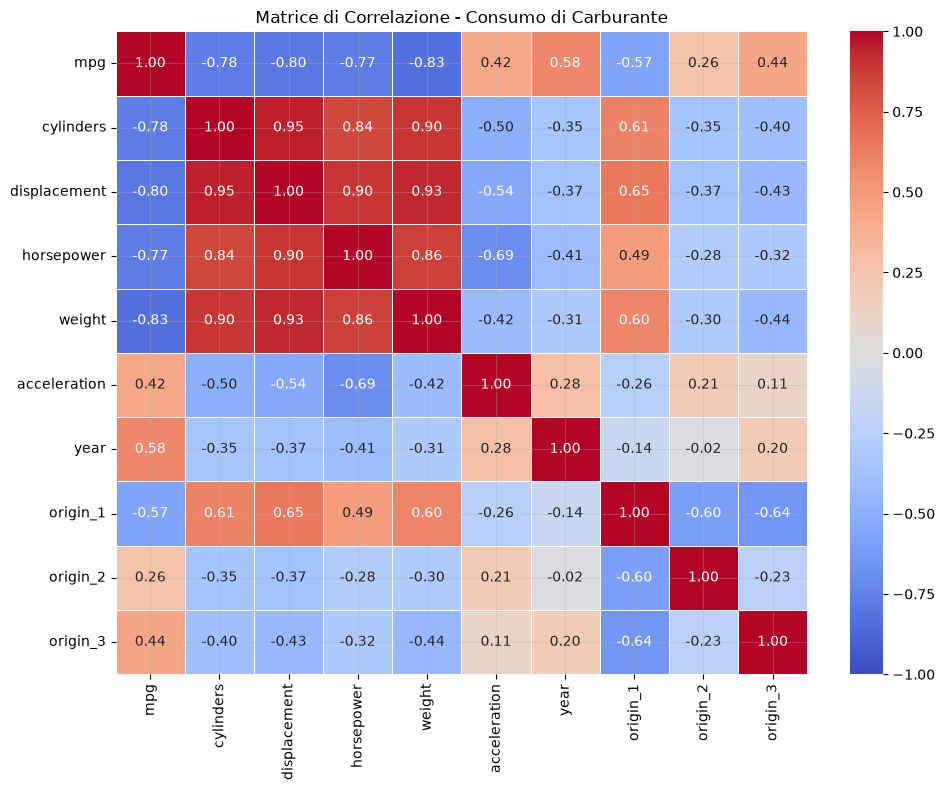

In [ ]:
# Statistiche descrittive principali
print("Statistiche descrittive:")
print(df_clean.describe().round(1))
#Calcolo della matrice di correlazione per vedere quali feature influenzano maggiormente 
print("\n--- PASSO 2: ANALISI CORRELAZIONE ---")
corr_matrix = df_clean.corr(numeric_only=True) #calcolo della matrice di 
#correlazione tra tutte le feature numeriche, per vedere quali feature
#influenzano maggiormente il consumo di carburante (mpg) e quali feature sono correlate tra loro.
#numeric_only=True serve a considerare solo le colonne numeriche per il calcolo della correlazione,
#così da evitare errori con colonne non numeriche.
print("Correlazione di ogni feature con mpg in ordine decrescente :")
print(corr_matrix["mpg"].sort_values(ascending=False)) #stampa la correlazione
#di ogni feature con mpg in ordine decrescente


# Generazione Heatmap di correlazione
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1) #coolwarm è una mappa di colori che va dal blu (bassa correlazione) al rosso (alta correlazione)
plt.title("Matrice di Correlazione - Consumo di Carburante") #fmt serve a formattare i valori numerici nella heatmap con 2 decimali e linewidths serve a separare le celle della heatmap con linee sottili
plt.tight_layout() #serve a ottimizzare il layout della figura per evitare sovrapposizioni di elementi
plt.savefig("correlazione_features.png") 
plt.show()



# 4° STEP #
## STAMPIAMO UN ISTOGRAMMA CHE RAPPRESENTA LA RELAZIONE DEL CONSUMO DEL CARBURANTE ##
Da qui capiamo la quantità di veicoli che consumano "tot"
## STAMPIAMO 3 (su 4) SCATTERPLOT DELLE FEATURE PIU' CORRELATE IN SENSO NEGATIVO CON IL CONSUMO DEL CARBURANTE ##
1. Peso del veicolo (libbre) vs MPG: è la correlazione più "negativa": significa che più il veicolo è pesante, meno chilometri per gallone riesce a fare.
2. Potenza cavalli vs MPG: negativa: significa che più cavalli il veicolo ha, meno chilometri per gallone riesce a fare
3. Cilindrata del motore (pollici cubi) vs MPG: negativa: significa che più è grande la cilindrata del veicolo, meno chilometri per gallone riesce a fare
## STAMPIAMO 1 SCATTERPLOT DELLA FEATURE PIU' CORRELATA IN SENSO POSITIVO CON IL CONSUMO DEL CARBURANTE ##
1. Anni (ultime 2 cifre) vs MPG: è la correlazione più "positiva": significa che più il veicolo è recente, più miglia per gallone riesce a fare. Questo è un dato positivo, perché significa che le auto più recenti sono più efficienti dal punto di vista del consumo di carburante.

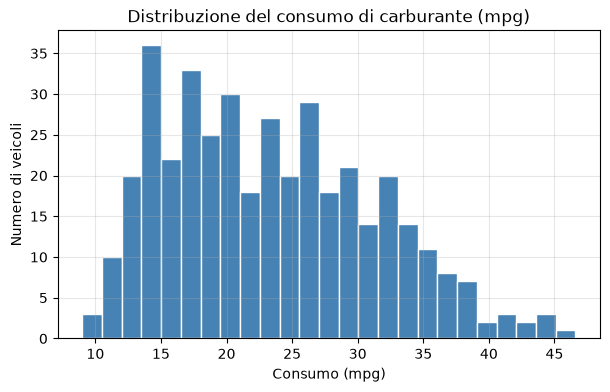

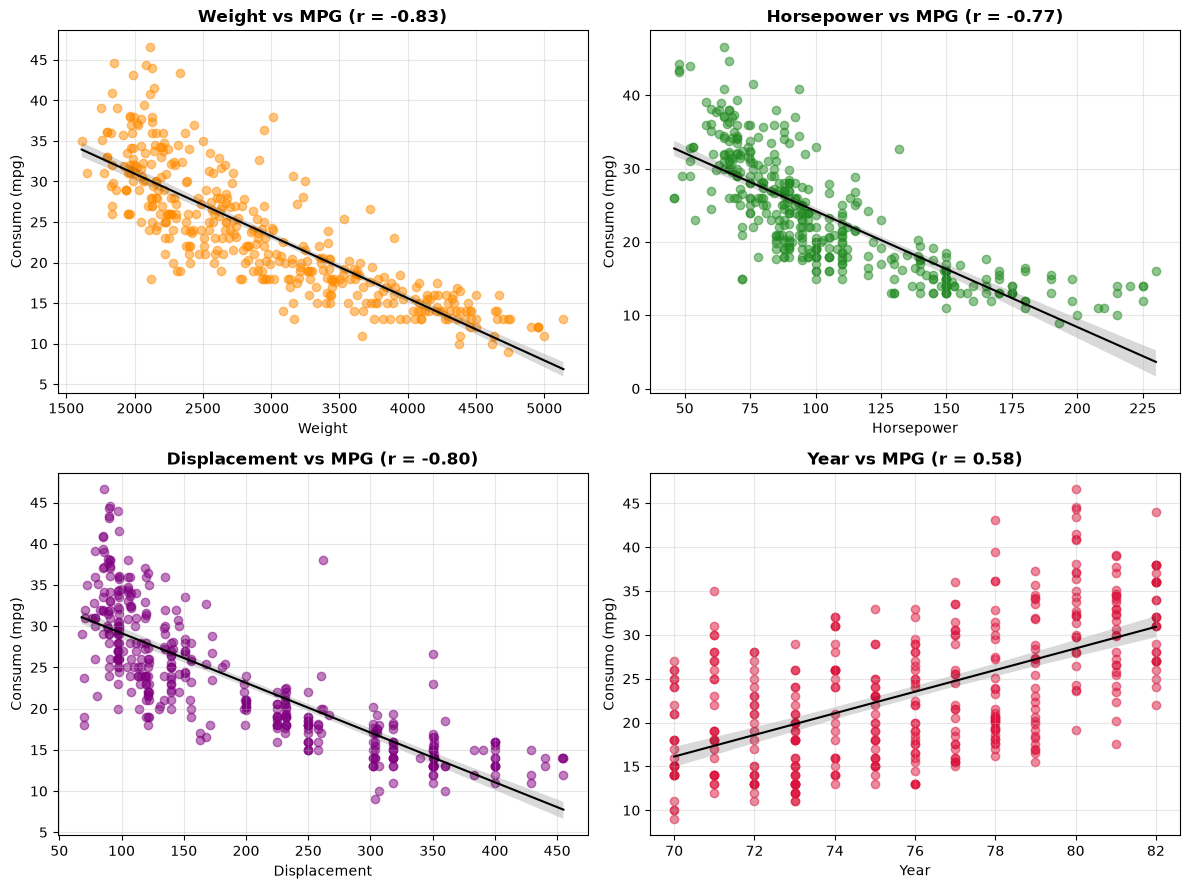

In [ ]:
# Distribuzione della variabile target
plt.figure()
plt.hist(df_clean["mpg"], bins=25, color="steelblue", edgecolor="white")
plt.xlabel("Consumo (mpg)")
plt.ylabel("Numero di veicoli")
plt.title("Distribuzione del consumo di carburante (mpg)")
plt.show()
# Selezioniamo le 4 feature con la correlazione più alta con mpg
top_features = ['weight', 'horsepower', 'displacement', 'year']

# Creiamo una griglia 2x2 per mettere a confronto i grafici
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()
# Palette di colori per distinguere le feature
colori = ['darkorange', 'forestgreen', 'purple', 'crimson']

for i, feature in enumerate(top_features):
    # regplot aggiunge sia i punti che la linea di tendenza lineare
    sns.regplot(
        data=df_clean, 
        x=feature, 
        y='mpg', 
        ax=axes[i],
        color=colori[i],
        scatter_kws={'alpha': 0.5},
        line_kws={'color': 'black', 'linewidth': 1.5}
    )
    
    # Recuperiamo il valore di correlazione per inserirlo nel titolo del subplot
    corr_val = corr_matrix.loc[feature, 'mpg']
    axes[i].set_title(f"{feature.capitalize()} vs MPG (r = {corr_val:.2f})", fontsize=12, fontweight='bold')
    axes[i].set_xlabel(feature.capitalize())
    axes[i].set_ylabel("Consumo (mpg)")

plt.tight_layout()
plt.savefig("relazioni_top_features_mpg.png", dpi=300)
plt.show()

# 5° STEP #
## SEPARAZIONE TRA FEATURE (X) E TARGET(y) ##
Al fine di preparare il dataset per l'addestramento del modello e per la valutazione delle performance del modello stesso
## DIVIDIAMO IL DATASET (80% TRAINING, 20% TEST) ##
Al fine di addestrare il modello e valutarne le performance su dati non visti durante l'addestramento  e quindi stimare la capacità di generalizzazione del modello stesso
## STANDARDIZZIAMO TRAMITE STANDARDSCALER ##
per migliorare le performance del modello e garantire che tutte le feature abbiano la stessa scala, evitando che alcune dominino altre a causa della loro grandezza.


In [50]:
# Separazione tra feature (X) e target (y) al fine di preparare il dataset per l'addestramento del modello e per la valutazione delle performance del modello stesso


X = df_clean.drop(columns=['mpg'])
y = df_clean['mpg']

# Divisione del dataset (80% training, 20% test)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# Standardizzazione tramite StandardScaler 

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns)

print(f"Dataset suddiviso: {X_train.shape[0]} train, {X_test.shape[0]} test.")



Dataset suddiviso: 317 train, 80 test.


# 6° STEP #
## ADDESTRIAMO IL MODELLO ##
Al fine di predire il consumo di carburante (mpg) in base alle feature selezionate e di valutare le performance del modello stesso
## FACCIAMO LA TABELLA DEI COEFFICIENTI STANDARDIZZATI ##
Per valutare l'impatto relativo delle feature sul consumo di carburante (mpg). I coefficenti servono a capire quanto una variazione di una feature (in termini di deviazioni standard) influenzi la variabile target (mpg). Un coefficiente positivo indica che all'aumentare della feature, aumenta anche il consumo di carburante, mentre un coefficiente negativo indica l'effetto opposto.


In [52]:
# Addestramento del modello
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Tabella dei coefficienti standardizzati 
df_coef = pd.DataFrame({
    'Feature': X.columns,
    'Coefficiente Standardizzato': model.coef_
}).sort_values(by='Coefficiente Standardizzato', key=abs, ascending=False)

print("\nIntercetta (beta_0):", round(model.intercept_, 4))
print("\nImpatto relativo delle feature (in Deviazioni Standard):")
print(df_coef.to_string(index=False))




Intercetta (beta_0): 23.3312

Impatto relativo delle feature (in Deviazioni Standard):
     Feature  Coefficiente Standardizzato
      weight                    -5.851908
        year                     2.894381
displacement                     2.394806
   cylinders                    -0.887411
    origin_1                    -0.624278
  horsepower                    -0.609207
    origin_2                     0.564495
    origin_3                     0.233485
acceleration                     0.077062


# 7° STEP #
## PREDIZIONI E METRICHE ##
Predizioni e Metriche servono a valutare le performance del modello sui dati di test. Gli indici MAE, RMSE e R² forniscono informazioni sulla precisione delle predizioni rispetto ai valori reali. piu bassi sono MAE e RMSE, migliore è la performance del modello. R² indica la proporzione di varianza spiegata dal modello, con valori più vicini a 1 che indicano un buon adattamento.
Nel nostro caso sono indici abbastanza "buoni" (MAE E RMSE bassi e R² abbastanza vicino all'1)
## CREIAMO IL GRAFICO(SCATTERPLOT) CHE CONFRONTA I VALORI REALI CON I VALORI PREDETTI ##
Il grafico mostra come i valori predetti dal modello si confrontano con i valori reali del consumo di carburante (mpg). La linea tratteggiata rappresenta la perfetta corrispondenza tra reale e predetto, quindi più i punti si avvicinano a questa linea, migliore è la performance del modello.
## CREIAMO IL GRAFICO(SCATTERPLOT) CHE RAPPRESENTA I VALORI RESIDUI ##
il grafico dei residui aiuta a verificare  se ci sono pattern nei residui, che potrebbero indicare problemi nel modello.




--- Metriche di Valutazione ---
MAE  : 2.90 mpg
RMSE : 3.72 mpg
R²   : 0.775
--- Metriche di Valutazione manuali ---
MAE (manuale): 2.90
MSE (manuale): 13.81
RMSE (manuale): 3.72
R² (manuale): 0.78


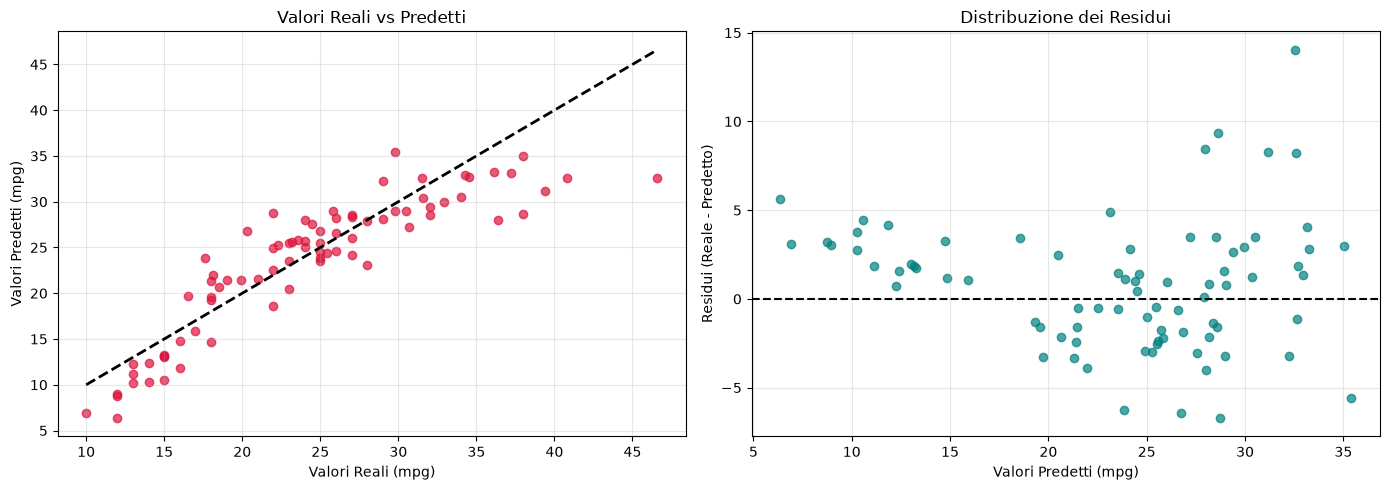

In [ ]:

# Predizioni e Metriche
y_pred = model.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n--- Metriche di Valutazione ---")
print(f"MAE  : {mae:.2f} mpg")
print(f"RMSE : {rmse:.2f} mpg")
print(f"R²   : {r2:.3f}")

#oppure manualmente
print("--- Metriche di Valutazione manuali ---")
error= y_test - y_pred
mae_manual = np.mean(np.abs(error))
print(f"MAE (manuale): {mae_manual:.2f}")
mse_manual = np.mean(error**2)
print(f"MSE (manuale): {mse_manual:.2f}")
rmse_manual = np.sqrt(mse_manual)
print(f"RMSE (manuale): {rmse_manual:.2f}")
r2_manual = 1 - (np.sum((y_test - y_pred) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2))
print(f"R² (manuale): {r2_manual:.2f}")


# Grafici Finali: Valori Reali vs Predetti e Residui
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Reali vs Predetti
axes[0].scatter(y_test, y_pred, alpha=0.7, color='crimson')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
axes[0].set_xlabel("Valori Reali (mpg)")
axes[0].set_ylabel("Valori Predetti (mpg)")
axes[0].set_title("Valori Reali vs Predetti")


# Subplot 2: Grafico dei Residui
residui = y_test - y_pred
axes[1].scatter(y_pred, residui, alpha=0.7, color='teal')
axes[1].axhline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_xlabel("Valori Predetti (mpg)")
axes[1].set_ylabel("Residui (Reale - Predetto)")
axes[1].set_title("Distribuzione dei Residui")

plt.tight_layout()
plt.show()